# Reproduction notebook

This notebook reruns, from scratch, the parts of this repository that can be rerun in a few minutes:

1. **An integrity run.** A short trajectory of the `polymer` preset goes through the whole pipeline: simulate, write a schema-3 HDF5 file, then analyse it with code that reads only that file. It tests the pipeline and is not a result.
2. **The passive-limit check** behind `results/validation/passive_wlc_check.png`. Eight seeds of a Pe = 0, 20-bond chain are compared with the exact statistics of the discrete worm-like chain, and the rerun's numbers are compared with the committed JSON.

It also reads back, without recomputing, the summary of the one 5 τ strong-spiral trajectory. That run took several days on a laptop and its 33 MB trajectory is not in git.

Nothing here is the 2020 summer-project code, and nothing here is a replication of Isele-Holder, Elgeti & Gompper, *Soft Matter* **11**, 7181 (2015).

**Runtime:** about two minutes on one CPU core, most of it the passive check. Outputs go to the git-ignored `output/notebook/`, so committed files are never overwritten.

In [1]:
import os, sys, json, time, platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, numba, h5py
import spinchain
print('repository:', ROOT.name)
print(f'spinchain {spinchain.__version__} | Python {platform.python_version()} | numpy {np.__version__} | '
      f'numba {numba.__version__} | h5py {h5py.__version__}')

repository: spin-chain-models-simulator
spinchain 2.0.0 | Python 3.11.18 | numpy 2.1.3 | numba 0.61.2 | h5py 3.13.0


## 1. Integrity run (not a result)

The `polymer` preset has Pe = 200, ξ_P/L = 0.2 and N = 100 bonds. The default non-bonded policy `lammps_default` is a hypothesis (see `AUDIT.md`), and dt = 5×10⁻⁵ is the code's stability guard, not a published value. 4 000 steps is 0.2 time units, about 8×10⁻⁷ τ: far too short for any of the paper's physics. The point is the pipeline and the provenance labels it writes.

In [2]:
from spinchain.paper import make
from spinchain.simulator import run
from spinchain.analysis import analyze

p = make('polymer')
path = 'output/notebook/polymer-4000.h5'
r = run(p, 4000, path, sample_every=100, overwrite=True)
print('completed:', r['completed'], '| steps:', r['step'], '| file:', r['output'])

z = analyze(path, window_tau=(0.0, None), window_reason='notebook integrity run: whole run, transient included')
c0, c1 = np.array(z['com_msd']['com_first']), np.array(z['com_msd']['com_last'])
print('replication status:', z['replication_status'])
print('non-bonded policy :', z['nonbonded_policy'], '-', z['nonbonded_policy_status'])
print('timestep status   :', z['timestep']['status'])
print(f'COM displacement  : {np.linalg.norm(c1 - c0):.4f} r0 (lab frame, never recentred)')
with h5py.File(path, 'r') as f:
    s = np.asarray(f['spiral'])
print(f'max |s| over run  : {np.max(np.abs(s)):.3f} (spiral number; no spiral is expected this early)')

completed: True | steps: 4000 | file: output/notebook/polymer-4000.h5
replication status: not a replication: analysis window 7.92e-07 tau < 5 tau
non-bonded policy : lammps_default - hypothesis: LAMMPS special_bonds lj 0 0 0 assumed; the paper's input script/ESI is unavailable
timestep status   : unpublished: dt is the code's stability guard 0.2*gamma/k_s, not the per-run ESI timestep
COM displacement  : 0.1269 r0 (lab frame, never recentred)
max |s| over run  : 0.137 (spiral number; no spiral is expected this early)


## 2. Passive-limit check of the bending term

At Pe = 0 the model is a discrete worm-like chain. With bond length $|\mathbf b_i| = r_0$, the printed bending energy of one joint is

$$\frac{\kappa}{4}\,|\mathbf b_i-\mathbf b_{i+1}|^2=\frac{\kappa r_0^2}{2}\,(1-\cos\theta_i).$$

In equilibrium the turning angles of a free chain are therefore independent, with $p(\theta)\propto e^{K\cos\theta}$ and $K=\kappa r_0^2/2k_BT$. This gives the exact results

$$\langle\cos\theta\rangle = \frac{I_1(K)}{I_0(K)} \equiv u,\qquad C(n)=\langle\mathbf t_i\cdot\mathbf t_{i+n}\rangle = u^n .$$

In spin-chain language, the unit bond tangents are planar spins with a nearest-neighbour ferromagnetic coupling $K k_BT\cos\theta$: a classical XY chain. The continuum worm-like chain instead has $C(s)=e^{-s/\xi_P}$ with $\xi_P=\kappa/k_BT$. At $K = 10$ the discrete chain's decay length $-r_0/\ln u$ is about 5 % shorter.

The check uses $K = 10$, the joint stiffness of all three Figure-2 presets ($\kappa = 20\,k_BT\,r_0$), on a 20-bond chain. A shorter chain is needed because the slowest bending mode of the 100-bond chain needs about $2\times10^4$ time units ($4\times10^8$ steps) to relax.

In [3]:
from spinchain.parameters import Parameters
from spinchain.validation import joint_stiffness, von_mises_mean_cos, discrete_persistence_length

q = Parameters(n_bonds=20, pe=0.0, xi_over_l=1.0)
K = joint_stiffness(q)
print(f'kappa = {q.kappa:g} kBT r0  ->  K = {K:g}')
print(f'exact <cos theta> = I1(K)/I0(K) = {von_mises_mean_cos(K):.6f}')
print(f'discrete decay length -r0/ln u = {discrete_persistence_length(K):.3f} r0 | continuum xi_P = kappa/kBT = {q.kappa/q.kbt:g} r0')
print('K of the Figure-2 presets:', [joint_stiffness(make(r)) for r in ('polymer', 'weak_spiral', 'strong_spiral')])

kappa = 20 kBT r0  ->  K = 10
exact <cos theta> = I1(K)/I0(K) = 0.948600
discrete decay length -r0/ln u = 18.951 r0 | continuum xi_P = kappa/kBT = 20 r0
K of the Figure-2 presets: [10.0, 10.0, 10.0]


Next, rerun the committed check, using the same function and fixed protocol as `python main.py wlc-check`. The rerun's numbers are then compared with `results/validation/passive_wlc_check.json`. The integrator and its counter-based noise are deterministic, so with the same platform and package versions the rerun is bitwise identical. On other platforms, expect agreement within the error bars.

In [4]:
from spinchain.validation import passive_wlc_check

t0 = time.perf_counter()
new = passive_wlc_check(out_dir='output/notebook', traj_dir='output/notebook/trajectories')
print(f'rerun took {time.perf_counter() - t0:.0f} s')

with open('results/validation/passive_wlc_check.json', encoding='utf8') as f:
    old = json.load(f)
for key in ('mean_cos', 'mean_cos_se', 'max_abs_z'):
    print(f"{key:12s} rerun = {new['results'][key]:.6f}   committed = {old['results'][key]:.6f}")
print(f"exact <cos theta>  = {new['theory']['mean_cos_exact_I1_over_I0']:.6f}")
diff = np.max(np.abs(np.asarray(new['results']['tangent_correlation_mean']) - np.asarray(old['results']['tangent_correlation_mean'])))
print(f'max |C_rerun(n) - C_committed(n)| = {diff:.2e}')
print('same physics fingerprints as the committed run:', new['run']['fingerprints'] == old['run']['fingerprints'])

rerun took 93 s
mean_cos     rerun = 0.948235   committed = 0.948235
mean_cos_se  rerun = 0.000580   committed = 0.000580
max_abs_z    rerun = 0.628910   committed = 0.628910
exact <cos theta>  = 0.948600
max |C_rerun(n) - C_committed(n)| = 0.00e+00
same physics fingerprints as the committed run: True


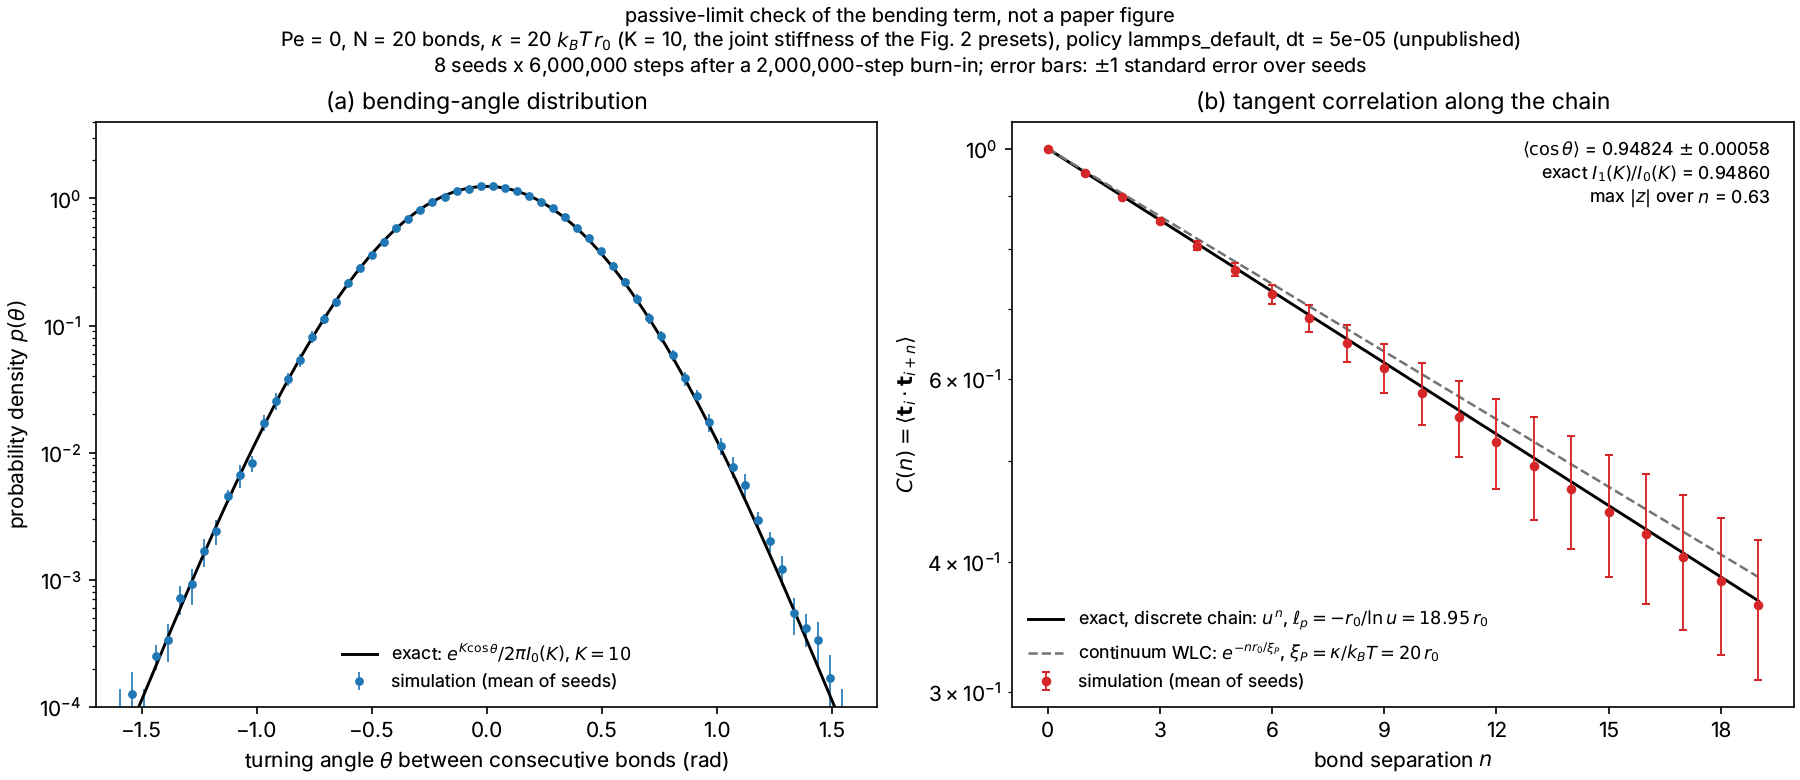

In [5]:
from IPython.display import Image, display
display(Image(filename=new['figure'], width=950))

**What the figure shows.** In (a), the simulated turning-angle density follows the exact Boltzmann distribution over four decades. In (b), C(n) follows the exact discrete result uⁿ within the seed-to-seed standard errors; the committed run's largest |z| over all separations is 0.63. At this stiffness it is also distinguishable from the continuum exponential. Together this checks the bending force, the thermal noise amplitude and the integrator. It says nothing about active filaments, and it is not a figure from the paper.

## 3. The 5 τ strong-spiral trajectory (read back, not rerun)

One trajectory (Pe = 5000, ξ_P/L = 0.2, N = 100, seed 12013, policy `paper_all_pairs`) was run for 5 τ, i.e. 2.525×10¹⁰ steps, on a laptop. Its stitched trajectory is not in git, so its verdict can only be read back here. The full account is in `RESULT_NOTE.md`.

In [6]:
with open('results/reproduction/verdict-paper_all_pairs-seed12013.json', encoding='utf8') as f:
    v = json.load(f)
print(v['note'])
w = v['window']
print(f"window: {w['rule']} ({w['start_tau']:g}-{w['end_tau']:g} tau, {w['samples']} samples every {w['sample_interval_contours']:g} contour)")
for k in ('duration_tau', 'fraction_abs_s_gt_2', 'beta2_symmetrized', 'longest_plateau_contours',
          'com_msd_loglog_slope', 'msr_unit_slope_region_exists', 'D_r', 'descriptions'):
    print(f'{k:30s} {v[k]}')
print('policy:', v['nonbonded_policy'], '-', v['nonbonded_policy_status'])
print('timestep:', v['timestep_status'])

not a replication; descriptions are not a claim that a figure was reproduced
window: drop the first 0.5 tau; no morphology cut (0.5-5 tau, 22501 samples every 0.25 contour)
duration_tau                   5.0
fraction_abs_s_gt_2            0.9784454024265589
beta2_symmetrized              1.0267910206866437
longest_plateau_contours       2007.75
com_msd_loglog_slope           1.0009423841557934
msr_unit_slope_region_exists   False
D_r                            None
descriptions                   ['predominant']
policy: paper_all_pairs - printed eq. (5): all pairs j>i
timestep: unpublished: dt is the code's stability guard 0.2*gamma/k_s, not the per-run ESI timestep


This is **one seed at one parameter point**. Another gated seed (12003) formed no spiral in 10 contours, so seed-to-seed behaviour is unknown. Pe = 200 and 1000 were not run at paper length, and no figure of the paper has been reproduced quantitatively. The longest plateau was still running when the run ended, so 2007.75 contours is a lower bound.

To recompute this summary on the machine that holds the trajectory, use the stitch, verdict and figure commands listed at the end of `RESULT_NOTE.md`.